In [21]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# En este bloque de código importo las funciones de la carpeta tools
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from tools.Newton import Newton
from tools.NewtonTabla import NewtonTabla

In [23]:
# Ejercicio 4
# Deflexion de la viga: y(x) = w0/(120*E*I*L) * (-x^5 + 2L^2 x^3 - L^4 x)
# Se busca la posicion x donde y(x) = -0.003, es decir y(x) + 0.003 = 0
# L = 2, w0 = 12x10^7, E = 2x10^11, I = 5x10^-4 y tolerancia 10^-6

#Datos del problema
L = 2
w0 = 12e7
E = 2e11
I = 5e-4
c = w0/(120*E*I*L)     # c = 0.005

#La deflexion de la viga
y = lambda x: c*(-x**5 + 2*L**2*x**3 - L**4*x)

#Introducir la funcion
f = lambda x: c*(-x**5 + 2*L**2*x**3 - L**4*x) + 0.003

#la derivada de la funcion
df = lambda x: c*(-5*x**4 + 6*L**2*x**2 - L**4)

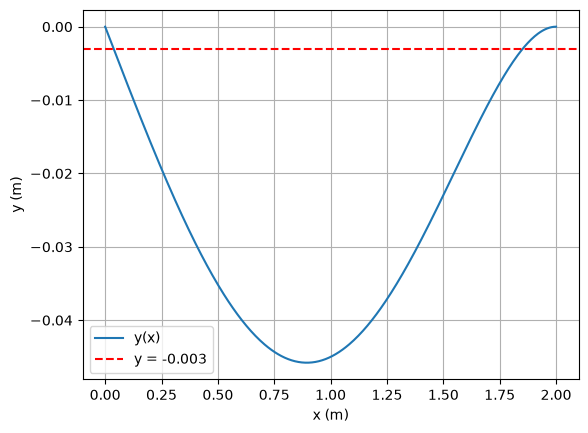

In [24]:
#Grafica de la viga para elegir la estimacion inicial
xs = np.linspace(0, L, 400)
plt.plot(xs, [y(t) for t in xs], label="y(x)")
plt.axhline(-0.003, color="r", ls="--", label="y = -0.003")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.grid()
plt.legend()
plt.show()

In [25]:
#Primera solucion: cerca del apoyo izquierdo

x0 = 0.5
tol = 1e-6
maxiter = 30

#obtenemos los resultados de la funcion Newton

x,iters,error = Newton(f,df,x0,tol,maxiter)

In [26]:
print(" La solucion de la ecuacion es: ", x)
print(" El numero de iteraciones fue: ", iters)
print(" El error fue: ", error)

 La solucion de la ecuacion es:  0.03752641830165473
 El numero de iteraciones fue:  4
 El error fue:  4.5647079231769805e-07


In [27]:
NewtonTabla(f,df,x0,tol,maxiter)

,x,Errores
Iteración,,
1,-0.1236363636,0.6236363636
2,0.0403038583,0.1639402220
3,0.0375259618,0.0027778965
4,0.0375264183,0.0000004565


In [28]:
#Segunda solucion: cerca del apoyo derecho

x0 = 1.5
tol = 1e-6
maxiter = 30

#obtenemos los resultados de la funcion Newton

x,iters,error = Newton(f,df,x0,tol,maxiter)

In [29]:
print(" La solucion de la ecuacion es: ", x)
print(" El numero de iteraciones fue: ", iters)
print(" El error fue: ", error)

 La solucion de la ecuacion es:  1.8522559531557519
 El numero de iteraciones fue:  5
 El error fue:  8.909324389350104e-10


In [30]:
NewtonTabla(f,df,x0,tol,maxiter)

,x,Errores
Iteración,,
1,1.8147783251,0.3147783251
2,1.8495196960,0.0347413709
3,1.8522372613,0.0027175654
4,1.8522559523,0.0000186909
5,1.8522559532,0.0000000009
